# Data exploration

Load the Swissgrid 2020-2025 files and extract the end-user consumption of the Swiss control block as a clean time series.

## Available sheets

We start with a thorough analysis of the 2024 file, because the statistics of this year have been fixed. Read the file. The yearly file contains several sheets. We first list them to find the one with the 15-minute values.

In [1]:
import pandas as pd

path = "../data/raw/EnergieUebersichtCH-2024.xlsx"
# sheet_name=None loads all sheets as a dict {sheet name: DataFrame}
sheets = pd.read_excel(path, sheet_name=None)
print(sheets.keys())

dict_keys(['Einstellungen', 'Datetime', 'Uebersicht', 'Zeitreihen0h15'])


## Load the 15-minute series

Fix correct sheet in file and dispense unnecessary rows and columns. Sheet 'Zeitreihen0h15': row 1 contains the column titles (save for labeling rows), row 2 the units (kWh, dispense), the data starts in row 3. Column A holds the timestamps, column B the end-user consumption.

In [2]:
df = pd.read_excel(
    path,
    sheet_name='Zeitreihen0h15',
    skiprows=[1],
    usecols='A:B',
)
# Check if loaded correctly
df.head()

,Unnamed: 0,Summe endverbrauchte Energie Regelblock Schweiz\nTotal energy consumed by end users in the Swiss controlblock
0,01.01.2024 00:15,1.443842e+06
1,01.01.2024 00:30,1.442366e+06
2,01.01.2024 00:45,1.432568e+06
3,01.01.2024 01:00,1.420472e+06
4,01.01.2024 01:15,1.445856e+06


In [3]:
# Check types of relevant consumption values
df.dtypes

Unnamed: 0                                                                                                           str
Summe endverbrauchte Energie Regelblock Schweiz\nTotal energy consumed by end users in the Swiss controlblock    float64
dtype: object

## Clean up

Short column names, timestamps parsed with an explicit format (day first),
timestamp as index. Each timestamp marks the end of a 15-minute interval.

The timestamps are Swiss local time (CET in winter, CEST in summer). Because of
the daylight saving time (DST) changes, one hour of labels is missing in March and one
hour is duplicated in October. We localize the timestamps to Europe/Zurich and
convert them to UTC, which gives a regular 15-minute grid (verified below).

In [4]:
df.columns = ["timestamps", "load"]
# Specify the format of the timestamps to avoid warnings about ambiguous times during DST transitions
df["timestamps"] = pd.to_datetime(df["timestamps"], format="%d.%m.%Y %H:%M")
df = df.set_index("timestamps")
# Specify the timezone of the timestamps to avoid warnings about ambiguous times during DST transitions
df.index = df.index.tz_localize("Europe/Zurich", ambiguous="infer")
df.index = df.index.tz_convert("UTC")
df.dtypes

load    float64
dtype: object

In [5]:
# Check if loaded correctly
df.head()

,load
timestamps,
2023-12-31 23:15:00+00:00,1.443842e+06
2023-12-31 23:30:00+00:00,1.442366e+06
2023-12-31 23:45:00+00:00,1.432568e+06
2024-01-01 00:00:00+00:00,1.420472e+06
2024-01-01 00:15:00+00:00,1.445856e+06


## Sanity check

Expected: 2024 is a leap year, so 366 days x 96 quarter hours = 35136 rows.
First timestamp 2023-12-31 23:15 UTC (2024-01-01 00:15 local time), last timestamp
2024-12-31 23:00 UTC (2025-01-01 00:00 local time). Timestamps mark the end of each
interval. No missing values, no duplicates, and all consecutive timestamps 15 minutes
apart (thanks to the conversion to UTC).

In [6]:
print(len(df))
print(df.index.min(), df.index.max())
# Number of missing or duplicated timestamps
print(df.isna().sum())
print(df.index.duplicated().sum())
# Check if the timestamps are evenly spaced
print(df.index.to_series().diff().value_counts())
# Check if there are any duplicated timestamps
print(df[df.index.duplicated(keep=False)])

35136
2023-12-31 23:15:00+00:00 2024-12-31 23:00:00+00:00
load    0
dtype: int64
0
timestamps
0 days 00:15:00    35135
Name: count, dtype: int64
Empty DataFrame
Columns: [load]
Index: []


## Units and hourly resolution

Swissgrid reports energy per quarter hour in kWh. We convert it to average power in MW (kWh per 15 min × 4 / 1000), the usual unit for grid load. Then we aggregate to hourly resolution, since we want to forecast hourly load. As timestamps mark the end of each interval, an hour is formed from the four quarter hours (h−1, h] and labelled with its end time h. Expected: 8784 entries (2024 is a leap year: 366 days × 24 hours). 

In [7]:
df["load_mw"] = df["load"] * 4 / 1000
# Calculate hourly mean load in MW, using right-closed intervals to avoid double-counting the last value of each hour
hourly = df[["load_mw"]].resample("h", closed="right", label="right").mean()
print(len(hourly))
hourly.head()

8784


,load_mw
timestamps,
2024-01-01 00:00:00+00:00,5739.248154
2024-01-01 01:00:00+00:00,5710.915366
2024-01-01 02:00:00+00:00,5576.793738
2024-01-01 03:00:00+00:00,5389.995073
2024-01-01 04:00:00+00:00,5235.865674


In [8]:
# Check if the hourly resampling worked correctly
hourly.describe()

,load_mw
count,8784.000000
mean,6075.715945
std,1144.678131
min,3612.828419
25%,5197.548500
50%,6000.023620
75%,6838.482289
max,9401.333995


Mean load about 6100 MW, range 3600–9400 MW. Annual energy ≈ 6076 MW × 8784 h ≈ 53 TWh, consistent with Swiss end-user consumption.

## Visual inspection

For plotting we convert back to Swiss local time, so that the axes show familiar clock times.

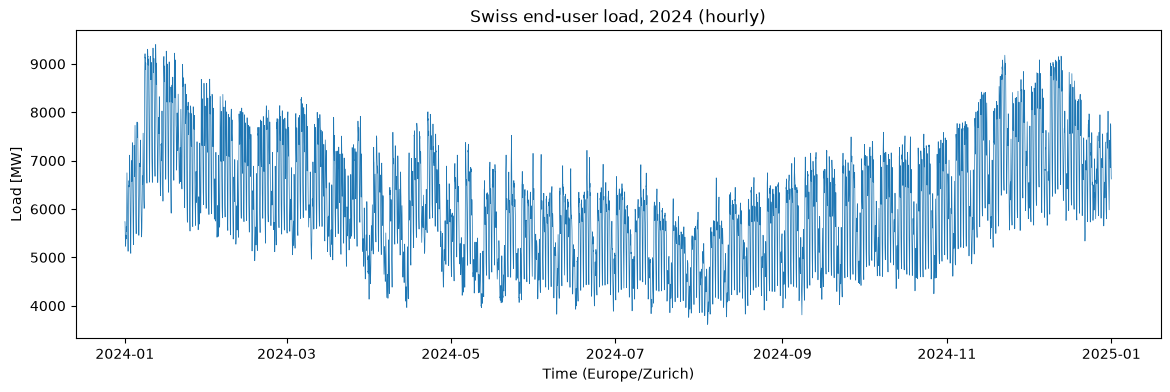

In [9]:
import matplotlib.pyplot as plt

# Plot hourly load in MW in local time (Europe/Zurich)
hourly_local = hourly.tz_convert("Europe/Zurich")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(hourly_local.index, hourly_local["load_mw"], linewidth=0.5)
ax.set_xlabel("Time (Europe/Zurich)")
ax.set_ylabel("Load [MW]")
ax.set_title("Swiss end-user load, 2024 (hourly)")
plt.show()

Clear annual seasonality: load is higher in winter (heating, lighting) than in summer. The thick band reflects the daily cycle. Regular dips correspond to weekends, the deepest one to the Christmas holidays; in both cases offices and much of industry are closed.

### One week

We zoom in on a typical week (Mon 4 – Sun 10 March 2024): no public holidays, no daylight saving change, neither mid-winter nor mid-summer. This makes the daily cycle and the weekday/weekend difference visible.

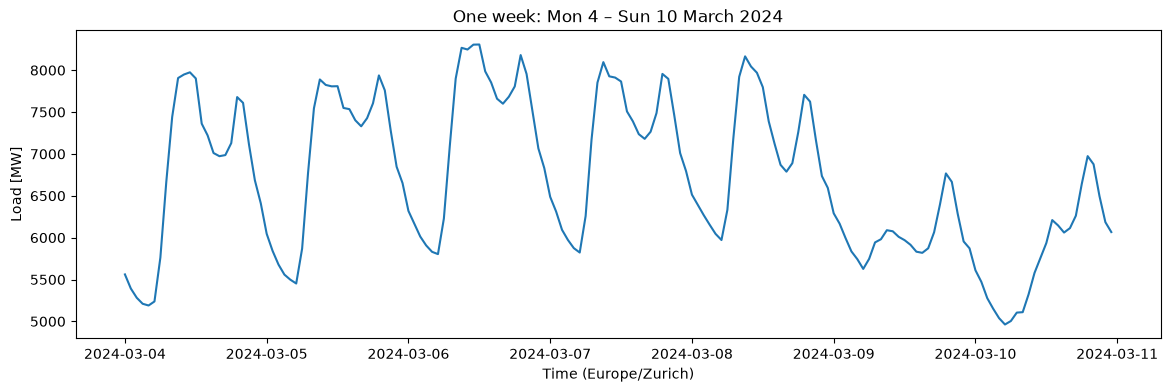

In [10]:
week = hourly_local.loc["2024-03-04":"2024-03-10"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(week.index, week["load_mw"])
ax.set_xlabel("Time (Europe/Zurich)")
ax.set_ylabel("Load [MW]")
ax.set_title("One week: Mon 4 – Sun 10 March 2024")
plt.show()

Five similar weekday profiles: low at night, steep ramp-up in the morning, a dip around noon (lunch break, and likely rooftop solar covering part of the demand behind the meter), and a decline in the evening. On the weekend the load is clearly lower and the morning ramp-up is weaker and later; activity concentrates in the afternoon.

### Average daily profile

For each hour of the day we average the load over all days of 2024, separately for weekdays (Mon–Fri) and weekends (Sat–Sun).

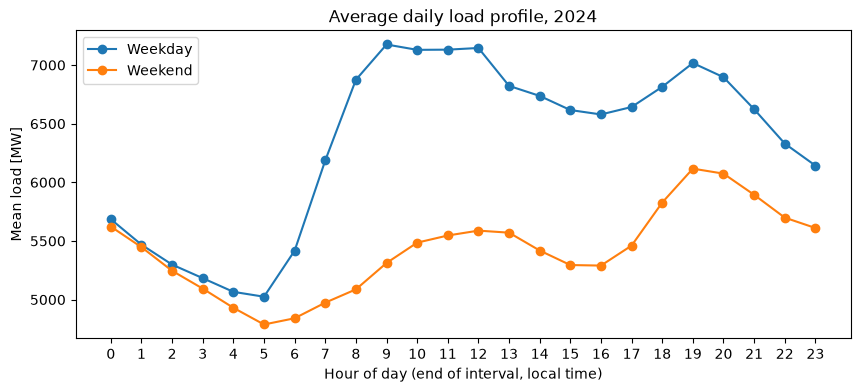

In [11]:
# Specify which days are weekends (Saturday=5, Sunday=6)
is_weekend = hourly_local.index.dayofweek >= 5

weekday = hourly_local[~is_weekend]
weekend = hourly_local[is_weekend]

weekday_profile = weekday.groupby(weekday.index.hour)["load_mw"].mean()
weekend_profile = weekend.groupby(weekend.index.hour)["load_mw"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekday_profile.index, weekday_profile.values, marker="o", label="Weekday")
ax.plot(weekend_profile.index, weekend_profile.values, marker="o", label="Weekend")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day (end of interval, local time)")
ax.set_ylabel("Mean load [MW]")
ax.set_title("Average daily load profile, 2024")
ax.legend()
plt.show()

## All years

The loading steps above are moved into the function `load_year` in `src/data.py`. We now apply it to **all** yearly files from 2020 to 2025 and repeat the sanity checks.

In [12]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
from src.data import load_year, load_all

In [13]:
# Check if all years can be loaded correctly
for year in range(2020, 2026):
    s = load_year(f"../data/raw/EnergieUebersichtCH-{year}.xlsx")
    print(year, len(s), s.index.min(), s.index.max(), s.isna().sum(), s.index.duplicated().sum())

2020 35136 2019-12-31 23:15:00+00:00 2020-12-31 23:00:00+00:00 0 0
2021 35040 2020-12-31 23:15:00+00:00 2021-12-31 23:00:00+00:00 0 0
2022 35040 2021-12-31 23:15:00+00:00 2022-12-31 23:00:00+00:00 0 0
2023 35040 2022-12-31 23:15:00+00:00 2023-12-31 23:00:00+00:00 0 0
2024 35136 2023-12-31 23:15:00+00:00 2024-12-31 23:00:00+00:00 0 0
2025 35040 2024-12-31 23:15:00+00:00 2025-12-31 23:00:00+00:00 0 0


### Data quirks

- **DST labels:** the labels around the October DST change differ between yearly files. In 2020 the repeated hour is labelled 02:15–03:00 (twice), which pandas cannot disambiguate with `ambiguous="infer"`, since 03:00 is not an ambiguous local time. `load_year` therefore builds the UTC grid from the first and last timestamps (both in winter time) and checks that the number of rows matches.
- **Label convention change in 2025:** from 2025 on, Swissgrid labels each quarter hour by its **start** (first timestamp 01.01.2025 00:00) instead of its end. We confirmed this by comparing the last value of 2024 and the first value of 2025, which carry the same label but differ. `load_year` detects the convention and shifts to end-of-interval labels.

All six years now cover their year completely and join without gaps or overlaps.

### Combined series 2020–2025

We concatenate all years into one series and check that the year boundaries join without gaps or overlaps. Expected: 210'432 quarter hours (two leap years, 2020 and 2024, with 366 × 96 = 35,136 each, and four regular years with 365 × 96 = 35,040 each), no duplicates, no missing values, and all consecutive timestamps 15 minutes apart.

In [14]:
load = load_all(range(2020, 2026), "../data/raw")
# Check if loaded correctly, number of rows, duplicates, missing values, and time differences between consecutive rows
print(len(load))
print(load.index.duplicated().sum())
print(load.isna().sum())
print(load.index.to_series().diff().value_counts())

210432
0
0
0 days 00:15:00    210431
Name: count, dtype: int64


In [15]:
# Calculate total energy consumption in TWh per year, using local time (Europe/Zurich) to determine the year of each timestamp
local_year = (load.index - pd.Timedelta(minutes=15)).tz_convert("Europe/Zurich").year
energy_twh = load.groupby(local_year).sum() / 1e9
print(energy_twh)

2020    54.659690
2021    56.792303
2022    55.451790
2023    53.478446
2024    53.369089
2025    53.495504
Name: load, dtype: float64


Annual end-user energy ranges from 53.4 to 56.8 TWh, with no jumps between years that would suggest a change in the measured quantity. The variation is plausible: lower demand in 2020 (COVID lockdown), a peak in 2021, and a decline from 2022 on (energy crisis, efficiency, rooftop solar consumed behind the meter).

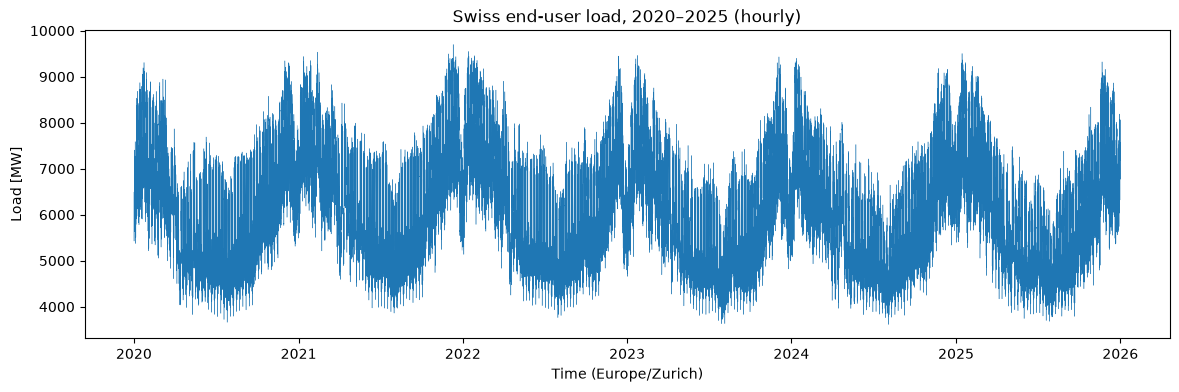

In [16]:
import matplotlib.pyplot as plt

load_mw_hourly = (load * 4 / 1000).resample("h", closed="right", label="right").mean()
load_mw_hourly_local = load_mw_hourly.tz_convert("Europe/Zurich")

# Plot hourly load in MW in local time (Europe/Zurich) for the entire period 2020–2025
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(load_mw_hourly_local.index, load_mw_hourly_local.values, linewidth=0.3)
ax.set_xlabel("Time (Europe/Zurich)")
ax.set_ylabel("Load [MW]")
ax.set_title("Swiss end-user load, 2020–2025 (hourly)")
plt.show()

The six years show a regular annual pattern (high in winter, low in summer) with a short dip around Christmas and New Year each year. No outliers, zeros or flat segments are visible.

In [17]:
# Save the cleaned series as Parquet (fast to reload, keeps index and time zone)
load.to_frame().to_parquet("../data/processed/load_2020_2025.parquet")

In [18]:
# Check that the saved file reloads identically, including the time zone
check = pd.read_parquet("../data/processed/load_2020_2025.parquet")["load"]
print(check.equals(load), check.index.tz)

True UTC
